In [17]:
# ==========================================
# Cell 1: Imports and Directory Setup
# ==========================================
import os
import glob
import pickle
import numpy as np 
from astropy.io import fits
from astropy.table import Table, vstack
from astropy.visualization import make_lupton_rgb
import matplotlib.pyplot as plt
from tqdm import tqdm
from lsst.daf.butler import Butler
from slsim.LsstSciencePipeline import lsst_science_pipeline

from utils import extract_non_lens_properties, robust_batch_lens_injection, patch_is_crowded, plot_injected_montage, plot_noise_std_histograms

import warnings
warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

img_dir = "../data_injected/non-lenses/images/"
table_dir = "../data_injected/non-lenses/"
os.makedirs(img_dir, exist_ok=True)
os.makedirs(table_dir, exist_ok=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# ==========================================
# Cell 2: Load Non-Lens Objects
# ==========================================
non_lens_categories = ["gal_gal_agn", "qso_gal", "qso_qso", "qso_star", "star_star"]
has_light = ["gal_gal_agn", "qso_gal", "cusp_mimic"]

# Sorted within each category so object order (and hence Object IDs) is identical across runs
category_files = {cat: sorted(glob.glob(f"../saved_objects/nonlenses_{cat}_*.pkl")) for cat in non_lens_categories}

all_non_lenses = []
category_counts = {}
print("Loading non-lens objects...")
for cat in non_lens_categories:
    cat_objects = []
    for file in category_files[cat]:
        with open(file, "rb") as f:
            cat_objects.extend(pickle.load(f))
            print(f"Loaded {cat} objects from {file}")
    all_non_lenses.extend(cat_objects)
    category_counts[cat] = len(cat_objects)

print(f"Total non-lenses loaded: {len(all_non_lenses)}")
num_lenses = len(all_non_lenses)


Loading non-lens objects...
Loaded gal_gal_agn objects from ../saved_objects/nonlenses_gal_gal_agn_10000.pkl
Loaded qso_gal objects from ../saved_objects/nonlenses_qso_gal_10000.pkl
Loaded qso_qso objects from ../saved_objects/nonlenses_qso_qso_10000.pkl
Loaded qso_star objects from ../saved_objects/nonlenses_qso_star_10000.pkl
Loaded star_star objects from ../saved_objects/nonlenses_star_star_10000.pkl
Total non-lenses loaded: 50000


In [4]:
# ==========================================
# Cell 3: Extract Properties (reuse cached table if present)
# ==========================================
base_table_path = os.path.join(table_dir, "table_non_lenses_base.fits")

if os.path.exists(base_table_path):
    print(f"Base catalog already exists, loading from {base_table_path}")
    table_non_lenses = Table.read(base_table_path, format="fits")
else:
    print("Extracting properties by category...")
    all_tables = []
    cat_track_index = 0
    for cat in non_lens_categories:
        # Slice from the already-loaded list so extraction order exactly matches all_non_lenses
        cat_objects = all_non_lenses[cat_track_index: cat_track_index + category_counts[cat]]
        has_central = cat in has_light
        cat_table = extract_non_lens_properties(
            cat_objects, has_central_object=has_central, starting_index=cat_track_index
        )
        all_tables.append(cat_table)
        cat_track_index += category_counts[cat]
        print(f"Processed {cat} (Central light: {has_central})")
    table_non_lenses = vstack(all_tables)
    table_non_lenses.write(base_table_path, format="fits", overwrite=True)
    print(f"Saved base catalog to {base_table_path}")


Base catalog already exists, loading from ../data_injected/non-lenses/table_non_lenses_base.fits


In [5]:
table_non_lenses

Object ID,RA,Dec,z_central,mag_lens_g,mag_lens_r,mag_lens_i,mag_lens_z,mag_lens_y
bytes12,float64,float64,float64,float64,float64,float64,float64,float64
D1_N00000000,253.39884826831647,-5.597020822468721,0.6551609940261384,28.065419420372493,26.804820496089093,25.718149849167276,25.31441991109898,25.01837787740702
D1_N00000001,216.64943671619292,-35.10308613995255,0.9474052864418853,24.814982684291362,22.75354888284325,21.666548042058654,20.739344876272117,20.34281328923161
D1_N00000002,178.409874962526,-17.47098407858364,0.9029296341342866,22.941304001330494,22.69174794082236,22.105073585475253,21.56956209898108,21.289983582816667
D1_N00000003,287.8933342026711,-47.310746973903676,0.5485393851896125,23.752051861020274,22.53185062138544,21.63059031916878,21.241949289687387,20.981590063896828
D1_N00000004,30.8657905370611,-58.505907545800994,0.4805397306550294,27.7581446050838,26.339958078764866,25.55096583471495,25.185871984644784,24.976528100231683
D1_N00000005,303.0342158070582,-55.025801945598786,0.585082835869243,27.94429069104571,26.683896185110804,25.665649019255838,25.2850609806678,25.023637357380807
D1_N00000006,317.35075175141486,-63.98201389502879,0.5489621103817292,23.469865206662533,22.25005744080869,21.357975086626496,20.985384905259394,20.73816762106094
D1_N00000007,107.92948383758566,-7.670538795820434,2.3015901687726026,25.701244092723684,25.556627475685517,25.424793672226357,25.24628364176072,24.703929682922038
D1_N00000008,296.2287052720637,-21.40987620330418,0.4485714384231576,22.17018874001743,20.729842003797764,20.059254829527802,19.725193926018726,19.51017409830741


In [6]:
# ==========================================
# Cell 4: Initialize Butler and Injection Parameters
# ==========================================
print("Initializing Butler...")
butler = Butler("dp02", collections="2.2i/runs/DP0.2")

band_list = ['g', 'r', 'i', 'z', 'y']
num_pix = 41
pixel_scale = 0.2
transform_matrix = np.array([[pixel_scale, 0], [0, pixel_scale]])

lenses_per_patch = 1000


Initializing Butler...


In [7]:
# ==========================================
# Cell 5: Resume Check (skip non-lenses already injected on disk)
# ==========================================
def find_completed_ids(img_dir, band_list):
    """Return {obj_id: (ra, dec)} for objects that already have all bands saved on disk."""
    completed = {}
    suffix = f"_{band_list[0]}.fits"
    for fpath in glob.glob(os.path.join(img_dir, f"*{suffix}")):
        obj_id = os.path.basename(fpath)[: -len(suffix)]
        if all(os.path.exists(os.path.join(img_dir, f"{obj_id}_{b}.fits")) for b in band_list):
            with fits.open(fpath) as hdul:
                ra = hdul[0].header.get("RA_OBJ", np.nan)
                dec = hdul[0].header.get("DEC_OBJ", np.nan)
            completed[obj_id] = (ra, dec)
    return completed

completed = find_completed_ids(img_dir, band_list)
print(f"Found {len(completed)} non-lenses already injected on disk. Resuming from there...")

successful_indices = []
pending_indices = []
for i, obj_id in enumerate(table_non_lenses["Object ID"]):
    if obj_id in completed:
        ra, dec = completed[obj_id]
        table_non_lenses[i]["RA"] = ra
        table_non_lenses[i]["Dec"] = dec
        successful_indices.append(i)
    else:
        pending_indices.append(i)

print(f"{len(pending_indices)} non-lenses remaining to inject.")


Found 8000 non-lenses already injected on disk. Resuming from there...
42000 non-lenses remaining to inject.


In [8]:
# ==========================================
# Cell 6: Batch Injection and Rendering
# ==========================================
attempt_counts = {}
max_patch_attempts = 40  # safety valve for an object that can never find a valid patch

print(f"Starting batch injection of {len(pending_indices)} remaining non-lenses into DP0 images...")

with tqdm(total=num_lenses, initial=len(successful_indices)) as pbar:
    while pending_indices:
        batch_indices = pending_indices[:lenses_per_patch]
        remaining_after_batch = pending_indices[lenses_per_patch:]
        current_lens_batch = [all_non_lenses[i] for i in batch_indices]

        # Random RA/Dec within the DP0.2 WFD footprint
        ra = np.random.uniform(55.0, 70.0)
        dec = np.random.uniform(-43.0, -30.0)

        try:
            coadd_list, coadd_nImage_list, _, variance_map_list = lsst_science_pipeline.get_dp0_images(
                butler=butler, ra=ra, dec=dec, band_list=band_list, coadd_injection=True
            )
            mag_zero_list = [2.5 * np.log10(coadd.getPhotoCalib().getInstFluxAtZeroMagnitude()) for coadd in coadd_list]
        except Exception as e:
            continue

        # Cheap pre-check: skip whole patches too crowded to be worth a full batch attempt
        if patch_is_crowded(coadd_list, variance_map_list, band_list, pixel_scale, num_pix):
            continue

        # lens_ids=batch_indices: match results back to the table by row index,
        # NOT by lens.generate_id() - that string is built from a couple of
        # rounded physical parameters and is not guaranteed unique across a
        # large/"balanced" sample, so it can silently collide between objects.
        batch_results, batch_failures = robust_batch_lens_injection(
            lens_batch=current_lens_batch,
            lens_ids=batch_indices,
            num_pix=num_pix,
            coadd_list=coadd_list,
            coadd_nImage_list=coadd_nImage_list,
            mag_zero_list=mag_zero_list,
            variance_map_list=variance_map_list,
            transform_matrix=transform_matrix,
            band_list=band_list,
            coadd_year=1,
            max_retries=10,
            snr_threshold=5,
            verbose=False,
        )

        succeeded_indices = set()
        for sample in batch_results:
            idx = sample["row_id"]
            obj_id = table_non_lenses[idx]["Object ID"]

            table_non_lenses[idx]["RA"] = sample["cutout_center"][0]
            table_non_lenses[idx]["Dec"] = sample["cutout_center"][1]

            for band in band_list:
                hdr = fits.Header()
                hdr["RA_OBJ"] = sample["cutout_center"][0]
                hdr["DEC_OBJ"] = sample["cutout_center"][1]
                fits_path = os.path.join(img_dir, f"{obj_id}_{band}.fits")
                fits.writeto(fits_path, sample["injected_images"][band], header=hdr, overwrite=True)

            successful_indices.append(idx)
            succeeded_indices.add(idx)
            pbar.update(1)

        still_pending = []
        for i in batch_indices:
            if i in succeeded_indices:
                continue
            reason = batch_failures.get(i, "unknown")
            obj_id_i = table_non_lenses[i]["Object ID"]
            if reason.startswith("exception"):
                tqdm.write(f"Dropping {obj_id_i} (index {i}) permanently - {reason}")
                continue
            attempt_counts[i] = attempt_counts.get(i, 0) + 1
            if attempt_counts[i] >= max_patch_attempts:
                tqdm.write(f"Warning: giving up on {obj_id_i} (index {i}) after {max_patch_attempts} patch attempts ({reason}).")
                continue
            still_pending.append(i)

        tqdm.write(f"Patch: {len(succeeded_indices)}/{len(batch_indices)} injected, {len(still_pending)} requeued.")
        pending_indices = remaining_after_batch + still_pending

print(f"\nInjection complete! {len(successful_indices)}/{num_lenses} non-lenses successfully injected.")


Starting batch injection of 42000 remaining non-lenses into DP0 images...


 18%|█▊        | 9000/50000 [15:14<1:09:42,  9.80it/s]    

Patch: 1000/1000 injected, 0 requeued.


 20%|██        | 10000/50000 [29:27<1:11:46,  9.29it/s]   

Patch: 1000/1000 injected, 0 requeued.


 22%|██▏       | 11000/50000 [43:19<55:00, 11.82it/s]      

... (75 outputs left out)

 98%|█████████▊| 49000/50000 [9:32:29<01:25, 11.74it/s]    

Patch: 1000/1000 injected, 0 requeued.


100%|██████████| 50000/50000 [9:46:22<00:00,  1.19it/s]    


Patch: 1000/1000 injected, 0 requeued.

Injection complete! 50000/50000 non-lenses successfully injected.


In [9]:
# ==========================================
# Cell 7: Save Filtered Catalog and Zip
# ==========================================
successful_indices = sorted(successful_indices)
table_non_lenses_final = table_non_lenses[successful_indices]

table_path = os.path.join(table_dir, "table_non_lenses_injected.fits")
table_non_lenses_final.write(table_path, format="fits", overwrite=True)
print(f"Saved injected catalog to {table_path}")

import shutil
shutil.make_archive(os.path.join(table_dir, "non_lenses_injected_images"), 'zip', img_dir)
print(f"✅ All images zipped to {os.path.join(table_dir, 'non_lenses_injected_images.zip')}")
zip_file_size = os.path.getsize(os.path.join(table_dir, "non_lenses_injected_images.zip")) / (1024 ** 3)
print(f"✅ Zip file size: {zip_file_size:.2f} GB")


Saved injected catalog to ../data_injected/non-lenses/table_non_lenses_injected.fits
✅ All images zipped to ../data_injected/non-lenses/non_lenses_injected_images.zip
✅ Zip file size: 3.09 GB


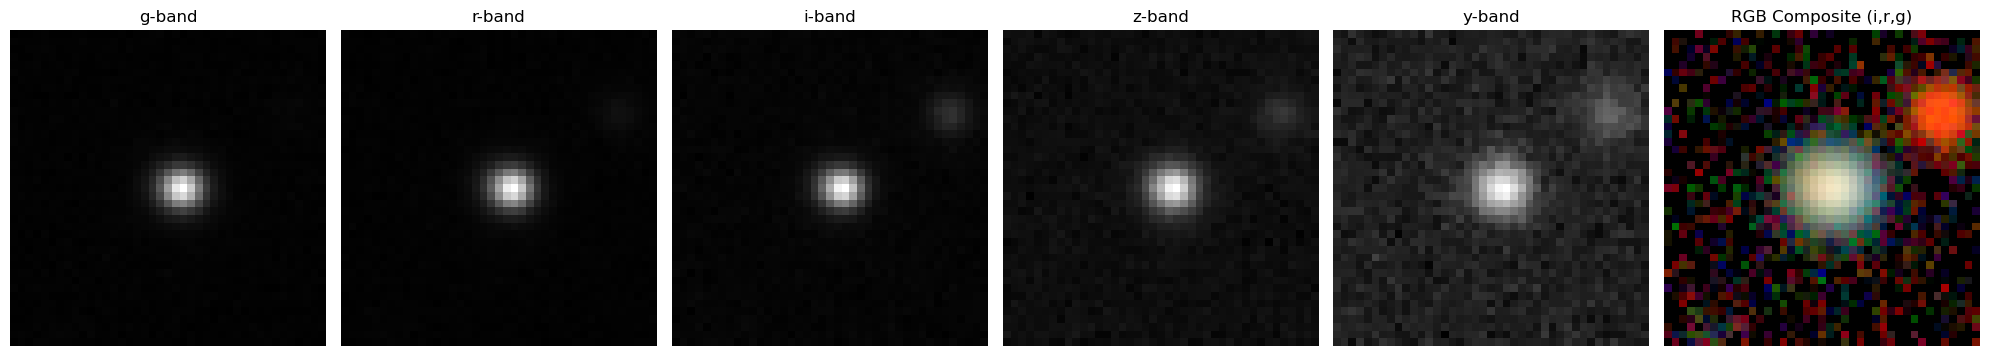

In [12]:
# ==========================================
# Cell 8: Verification - Load and Display a Saved Non-Lens
# ==========================================
sample_id = table_non_lenses_final["Object ID"][799]

test_loaded_image = {}
for band in band_list:
    with fits.open(os.path.join(img_dir, f"{sample_id}_{band}.fits")) as hdul:
        test_loaded_image[band] = hdul[0].data

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for i, band in enumerate(band_list):
    axes[i].imshow(test_loaded_image[band], cmap='gray', origin='lower')
    axes[i].set_title(f"{band}-band")
    axes[i].axis('off')

rgb_image = make_lupton_rgb(test_loaded_image['i'], test_loaded_image['r'], test_loaded_image['g'], stretch=0.5)
axes[5].imshow(rgb_image, origin='lower')
axes[5].set_title("RGB Composite (i,r,g)")
axes[5].axis('off')
plt.tight_layout()
plt.show()


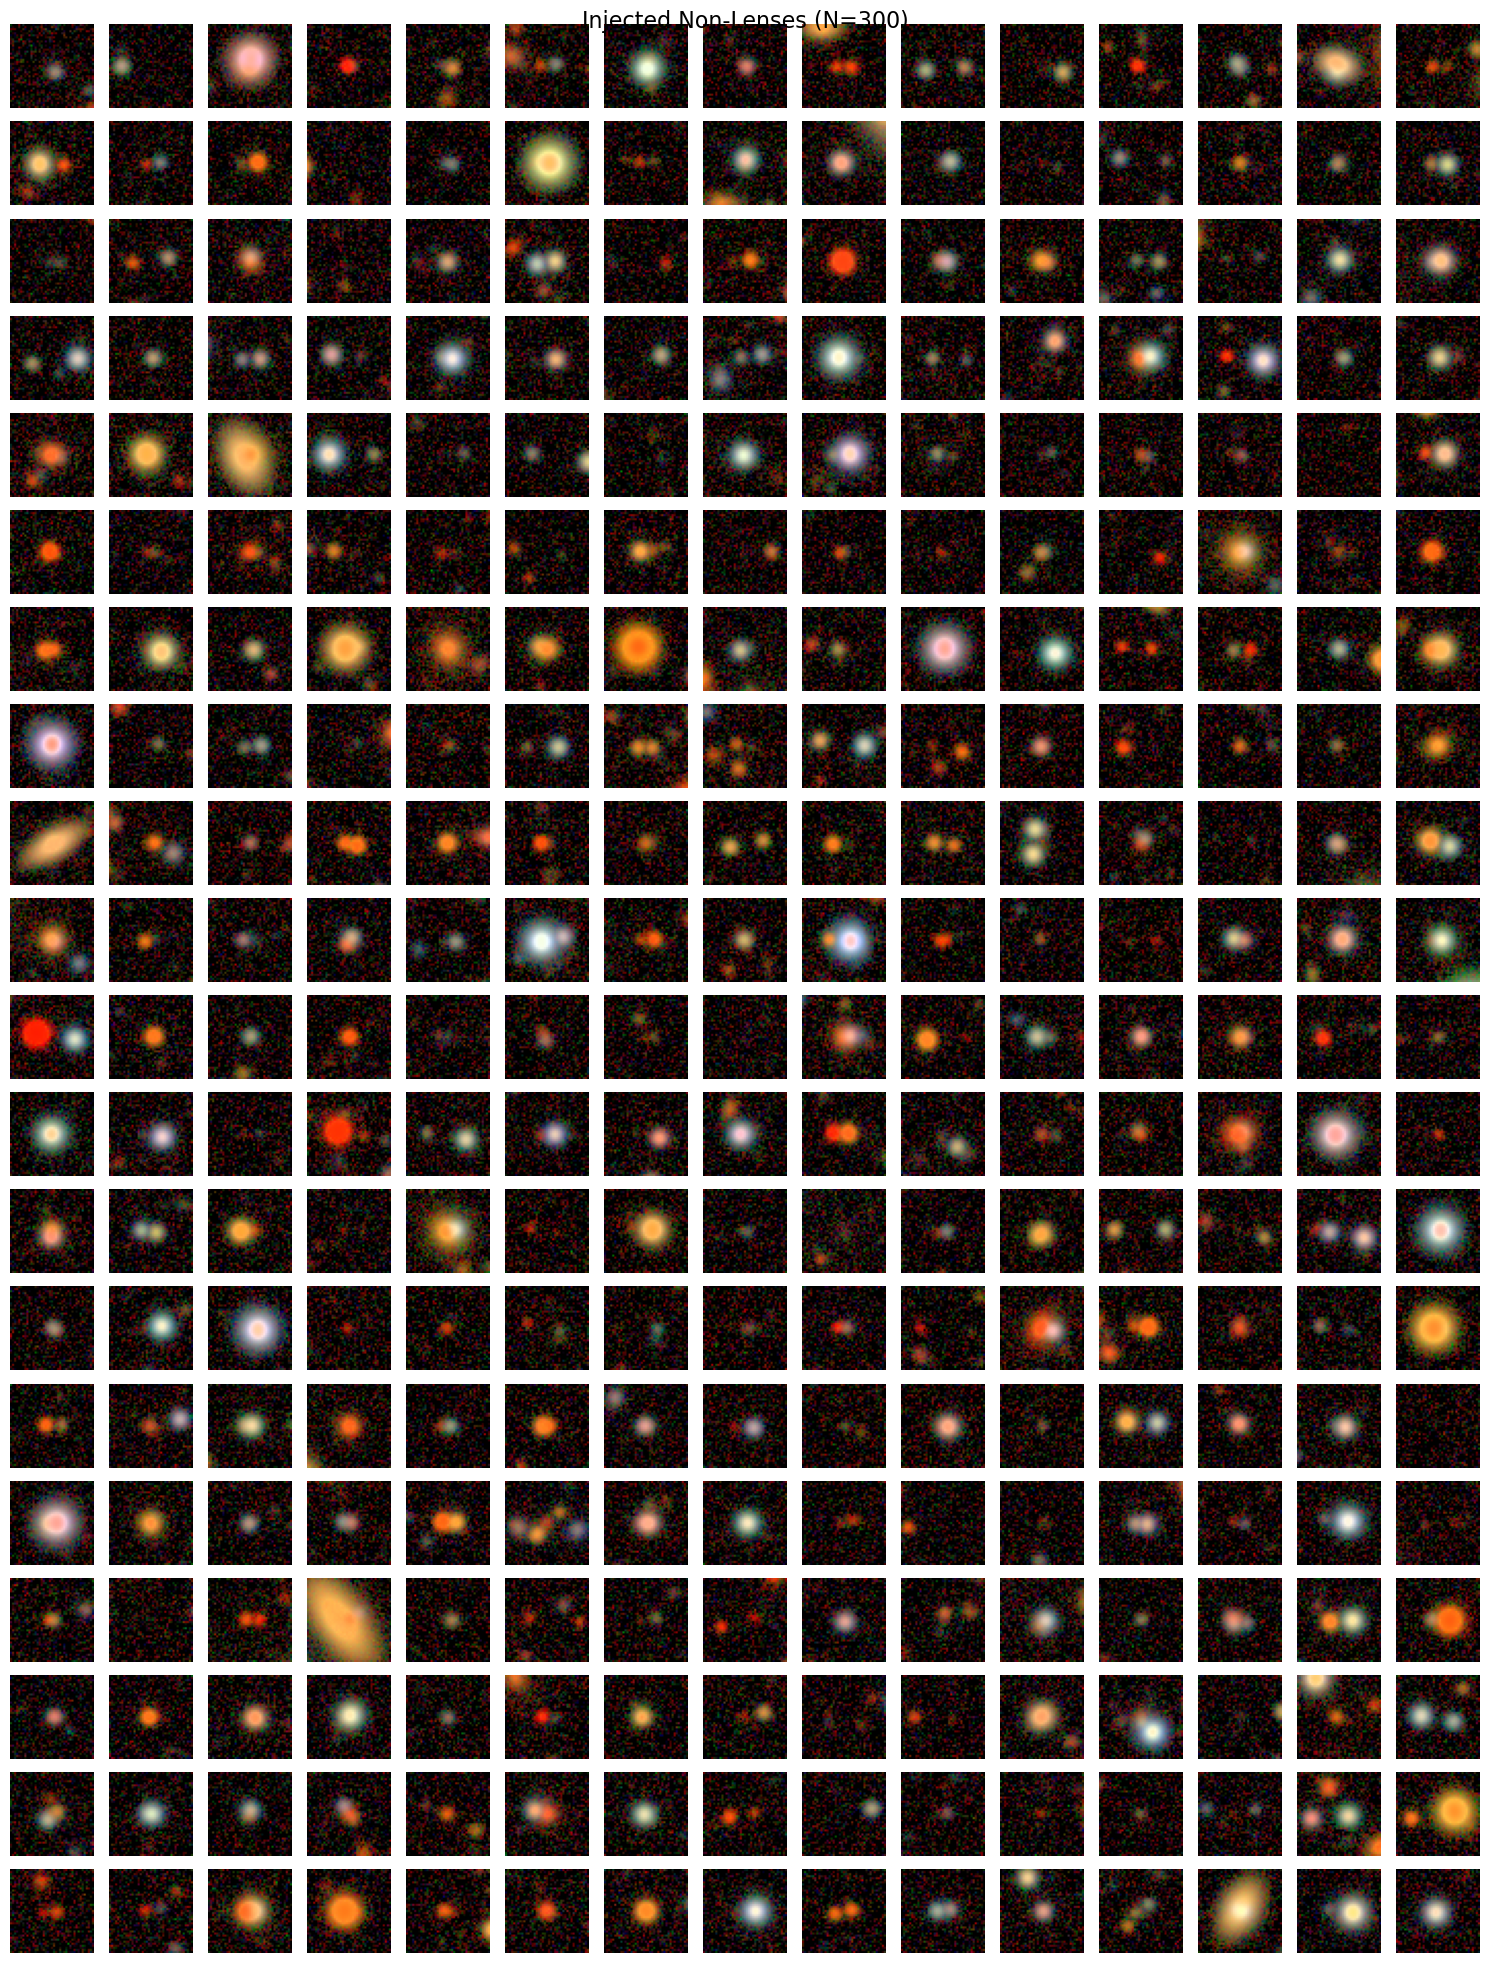

In [19]:
# ==========================================
# Cell 9: Montage - Visualize Injected Non-Lenses
# ==========================================

test_ids = [table_non_lenses_final[i]["Object ID"] for i in np.random.randint(0,50000, 300)]

plot_injected_montage(
    test_ids,
    img_dir,
    band_list=band_list,
    rgb_bands=['i', 'r', 'g'],
    num_cols=15,
    plot_title=f"Injected Non-Lenses (N={len(test_ids)})",
)
plt.show()


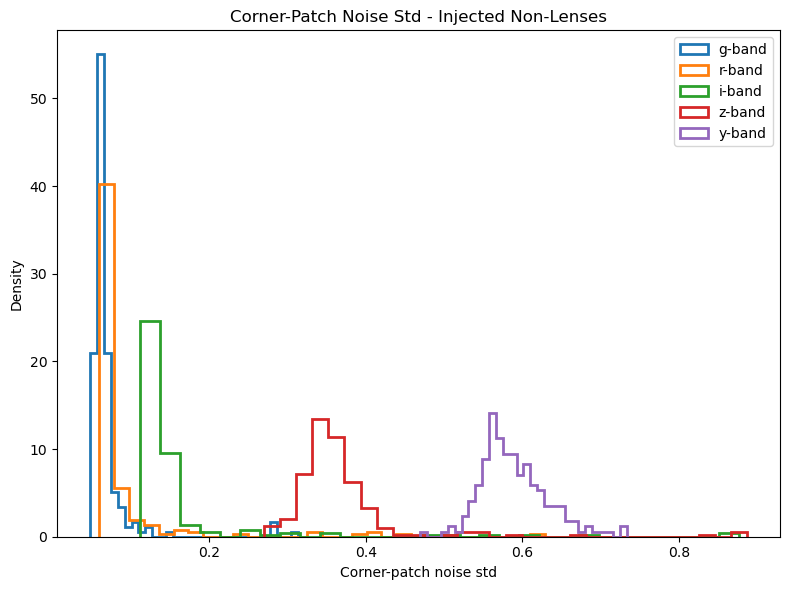

In [18]:
# ==========================================
# Cell 10: Noise Check - Corner-Patch Noise Std per Band
# ==========================================
plot_noise_std_histograms(
    test_ids,
    img_dir,
    band_list=band_list,
    corner_size=9,
    plot_title="Corner-Patch Noise Std - Injected Non-Lenses",
)
plt.show()
